# Who's Checking the Checkers?
## PCAOB inspection results and audit partner workload
**AC 547 Final Project, Group 13 (Track A: Analyze)**

**Research question:** How have PCAOB Part I.A deficiency rates changed over time across audit firm tiers, and do firms whose engagement partners carry more public company clients have higher deficiency rates?

This notebook produces **every number and chart in our presentation**. Section 14 tests each deck figure against the computed result, so a reader can confirm the slides match the data.

**Data sources (both public, from pcaobus.org):**
1. `inspection-reports-json.json`: Firm Inspection Reports data set ("Firm Data and Audits Selected for Review"), one row per inspection report.
2. `FirmFilings.zip`: AuditorSearch (Form AP) full download, one row per Form AP filing.

**Design choices (also stated in the presentation):**
- Keep only regular public company audits (drop investment companies and employee benefit plans).
- Keep only the latest version of each Form AP filing (drop superseded amendments).
- Match inspection year *Y* to Form AP fiscal year *Y − 1*, because an inspection reviews the prior year's audits.
- Join the two sources on PCAOB firm ID, not firm name.
- Measure workload the same way for every firm: unique public company clients ÷ unique signing engagement partners, from Form AP.

**Unit of analysis:** one row = one firm in one inspection year. Workload is a **firm-level average**. We do not observe how many clients any individual partner has relative to the firm average, so results describe firms, not individual partners.

**Privacy:** Form AP contains individual partner names and contact details. This notebook never loads those columns. Partners are counted by ID number only.

## 1. Setup
Change `DATA_DIR` to the folder where you saved the two downloads.

In [1]:
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "."   # <-- change this to your folder
INSPECTION_FILE = f"{DATA_DIR}/inspection-reports-json.json"
FORM_AP_ZIP = f"{DATA_DIR}/FirmFilings.zip"

FIRST_INSPECTION_YEAR = 2018   # first year the detailed PCAOB data sets cover
LAST_INSPECTION_YEAR = 2025    # most recent year (incomplete; see Section 2)
TREND_LAST_YEAR = 2024         # trend chart stops at the last complete year

# PCAOB firm IDs for the U.S. Big 4 (verified against both files)
BIG4_IDS = {42: "Ernst & Young LLP", 34: "Deloitte & Touche LLP",
            238: "PricewaterhouseCoopers LLP", 185: "KPMG LLP"}

TIER_ORDER = ["Big 4", "Other annual", "Triennial"]
TIER_COLORS = {"Big 4": "#234E86", "Other annual": "#C8621E", "Triennial": "#B9A688"}

# Every figure quoted in the presentation is stored here and tested in Section 14
facts = {}

pd.set_option("display.width", 140)

## 2. Load and clean the inspection data
Every field in the JSON file arrives as text, so numeric fields are converted first.

We **recompute** the deficiency rate as deficient audits ÷ audits reviewed. That gives full precision (PCAOB's published field is rounded to a whole percent) and checks that the published figure agrees with its parts.

In [2]:
with open(INSPECTION_FILE) as f:
    ins = pd.DataFrame(json.load(f))

num_cols = ["InspectionYear", "AuditsWithPartIADeficiencies", "TotalAuditsReviewed",
            "PartIADeficiencyRate", "TotalIssuerAuditClients",
            "TotalEngagementPartnersOnIssuerAuditWork"]
for c in num_cols:
    ins[c] = pd.to_numeric(ins[c], errors="coerce")

ins = ins.rename(columns={"RegistrationId": "firm_id", "InspectionYear": "insp_year"})
print("All inspection reports:", len(ins))

ins = ins[ins["insp_year"].between(FIRST_INSPECTION_YEAR, LAST_INSPECTION_YEAR)].copy()
print(f"Reports in {FIRST_INSPECTION_YEAR}-{LAST_INSPECTION_YEAR}:", len(ins))

ins["def_rate"] = ins["AuditsWithPartIADeficiencies"] / ins["TotalAuditsReviewed"]
gap = (ins["def_rate"] * 100).round() - ins["PartIADeficiencyRate"]
print("Reports where recomputed rate differs from published rate by >1 point:",
      int((gap.abs() > 1).sum()))
print("Duplicate firm-year reports:", int(ins.duplicated(["firm_id", "insp_year"]).sum()))

reports_by_year = ins.groupby("insp_year").size().rename("reports")
facts["reports_last_year"] = int(reports_by_year.loc[LAST_INSPECTION_YEAR])
reports_by_year

All inspection reports: 4346
Reports in 2018-2025: 1237
Reports where recomputed rate differs from published rate by >1 point: 0
Duplicate firm-year reports: 0


insp_year
2018    168
2019    176
2020    153
2021    141
2022    157
2023    167
2024    171
2025    104
Name: reports, dtype: int64

**Data-quality note:** PCAOB issues inspection reports on a rolling basis, so the most recent year is incomplete (compare its report count above with earlier years). We keep it in the main sample, leave it out of the trend chart, and show in Section 12 that results are the same without it.

## 3. Assign firm tiers
Following our professor's suggestion:
- **Big 4**: the four U.S. Big 4 firms, by firm ID
- **Other annual**: other firms inspected every year (more than 100 public company audit clients)
- **Triennial**: firms inspected at least every three years (100 or fewer)

Foreign Big 4 network affiliates are inspected triennially, so they fall in the Triennial tier.

In [3]:
def tier(row):
    if row["firm_id"] in BIG4_IDS:
        return "Big 4"
    if row["InspectionType"] == "Annually Inspected":
        return "Other annual"
    return "Triennial"

ins["tier"] = ins.apply(tier, axis=1)
pd.crosstab(ins["tier"], ins["Country"].eq("United States").map({True: "U.S.", False: "Non-U.S."}))

Country,Non-U.S.,U.S.
tier,,
Big 4,0,32
Other annual,0,69
Triennial,455,681


## 4. Load and clean Form AP
Only the columns we need are loaded, which skips all name and contact fields.

1. Keep latest filings only (`Latest Form AP Filing == 1`).
2. Keep regular public company audits only.
3. Parse the fiscal period end date. **Note:** the data dictionary says mm/dd/yyyy, but the file actually stores `m/d/yyyy h:mm:ss AM`, so we parse the real format.
4. Build a client identifier. Some filings are missing the PCAOB Issuer ID, so we fall back to the SEC CIK. If both are missing, the filing counts as its own client.

In [4]:
AP_COLS = ["Form Filing ID", "Latest Form AP Filing", "Firm ID", "Audit Report Type",
           "Issuer ID", "Issuer CIK", "Fiscal Period End Date", "Engagement Partner ID"]

with zipfile.ZipFile(FORM_AP_ZIP) as z:
    csv_name = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
    ap = pd.read_csv(z.open(csv_name), usecols=AP_COLS, dtype=str)

print("All Form AP filings:", len(ap))
print(ap["Audit Report Type"].value_counts(), "\n")

n_all = len(ap)
all_ap_firm_ids = set(pd.to_numeric(ap["Firm ID"]).unique())   # used to test the ID link in Section 5
ap = ap[ap["Latest Form AP Filing"] == "1"]
facts["amendments_removed"] = n_all - len(ap)
print("Superseded amendments removed:", facts["amendments_removed"])

ap = ap[ap["Audit Report Type"] == "Issuer, other than Employee Benefit Plan or Investment Company"].copy()
facts["regular_audits_kept"] = len(ap)
print("Regular public company audits kept:", facts["regular_audits_kept"])

ap["fiscal_year"] = pd.to_datetime(ap["Fiscal Period End Date"],
                                   format="%m/%d/%Y %I:%M:%S %p", errors="coerce").dt.year
facts["dates_unparsed"] = int(ap["fiscal_year"].isna().sum())
print("Unparseable dates:", facts["dates_unparsed"])
print("Implausible fiscal years (before 2014):", int((ap["fiscal_year"] < 2014).sum()))

facts["missing_issuer_id"] = int(ap["Issuer ID"].isna().sum())
print("Missing Issuer ID:", facts["missing_issuer_id"],
      "| missing both Issuer ID and CIK:", int((ap["Issuer ID"].isna() & ap["Issuer CIK"].isna()).sum()))
ap["client_key"] = ("ID" + ap["Issuer ID"]).fillna("CIK" + ap["Issuer CIK"]).fillna("FILING" + ap["Form Filing ID"])

ap["firm_id"] = pd.to_numeric(ap["Firm ID"])
ap["fiscal_year"].value_counts().sort_index().loc[2014:]

All Form AP filings: 157325
Audit Report Type
Issuer, other than Employee Benefit Plan or Investment Company    91465
Investment Company                                                55748
Employee Benefit Plan                                             10112
Name: count, dtype: int64 

Superseded amendments removed: 5637
Regular public company audits kept: 86790
Unparseable dates: 0
Implausible fiscal years (before 2014): 21
Missing Issuer ID: 1082 | missing both Issuer ID and CIK: 406


fiscal_year
2014       30
2015      181
2016     6450
2017     8316
2018     7984
2019     7974
2020     9960
2021    10837
2022     8854
2023     8418
2024     8239
2025     8174
2026     1352
Name: count, dtype: int64

## 5. Build the workload measure and link the files
For each firm and fiscal year:
- **clients** = unique public company clients (`client_key`)
- **partners** = unique signing engagement partners (`Engagement Partner ID`)
- **clients_per_partner** = clients ÷ partners, the firm's average workload per signing partner

Each inspection year *Y* is then matched to fiscal year *Y − 1* by firm ID.

**Limitation:** a filing's fiscal year is the year its fiscal period *ended*, so for companies with non-December year-ends the one-year lag is approximate.

In [5]:
workload = (ap.groupby(["firm_id", "fiscal_year"])
              .agg(clients=("client_key", "nunique"),
                   partners=("Engagement Partner ID", "nunique"))
              .reset_index())
workload["clients_per_partner"] = workload["clients"] / workload["partners"]

ins["fiscal_year"] = ins["insp_year"] - 1
df = ins.merge(workload, on=["firm_id", "fiscal_year"], how="left")

# Link quality: share of inspection reports whose firm ID appears anywhere in Form AP
# (any year, any audit type). This tests the ID join itself, before our sample filters.
id_match = ins["firm_id"].isin(all_ap_firm_ids)
facts["firm_id_match_pct"] = round(id_match.mean() * 100)
facts["unmatched_triennial"] = int(((df["tier"] == "Triennial") & df["clients"].isna()).sum())
print(f"Inspection reports whose firm ID appears in Form AP: {facts['firm_id_match_pct']}%")
print("Triennial reports with no Form AP match for that year:", facts["unmatched_triennial"])

pd.crosstab(df["tier"], df["clients"].notna().map({True: "matched", False: "no Form AP match"}))

Inspection reports whose firm ID appears in Form AP: 97%
Triennial reports with no Form AP match for that year: 240


clients,matched,no Form AP match
tier,,
Big 4,32,0
Other annual,66,3
Triennial,896,240


Unmatched reports are most likely firms that did not sign any public company audit reports that year (for example, firms that only assisted on other firms' audits). They are dropped and the count is reported.

## 6. Validate the workload measure against firms' self-reported counts
The inspection file includes self-reported client and partner counts, **but only for triennial firms**. Where both exist, we compare them.

Client counts should agree closely. Partner counts should agree less, because the inspection file counts *all* partners on public company work, while Form AP counts only partners who *sign*.

In [6]:
v = df[df["clients"].notna()
       & df["TotalIssuerAuditClients"].notna()
       & df["TotalEngagementPartnersOnIssuerAuditWork"].notna()].copy()

facts["validation_client_corr"] = round(v[["TotalIssuerAuditClients", "clients"]].corr().iloc[0, 1], 2)
facts["validation_partner_corr"] = round(v[["TotalEngagementPartnersOnIssuerAuditWork", "partners"]].corr().iloc[0, 1], 2)
print("Reports available for validation:", len(v))
print("Correlation, clients: ", facts["validation_client_corr"])
print("Correlation, partners:", facts["validation_partner_corr"])
print("Median difference (self-reported minus Form AP): clients %.1f, partners %.1f" % (
    (v["TotalIssuerAuditClients"] - v["clients"]).median(),
    (v["TotalEngagementPartnersOnIssuerAuditWork"] - v["partners"]).median()))

Reports available for validation: 896
Correlation, clients:  0.93
Correlation, partners: 0.65
Median difference (self-reported minus Form AP): clients 0.0, partners 0.0


## 7. Build the analysis sample
The table below is the sample-selection table for our methods discussion.

In [7]:
steps = [("Inspection reports in period", len(df))]
s = df[df["clients"].notna()]
steps.append(("Has a Form AP workload match", len(s)))
s = s[s["TotalAuditsReviewed"] > 0].copy()
steps.append(("At least one audit reviewed", len(s)))

s["log_cpp"] = np.log(s["clients_per_partner"])   # log scale: each doubling counts the same

facts["sample_reports"] = len(s)
facts["sample_firms"] = s["firm_id"].nunique()
pd.DataFrame(steps, columns=["Step", "Reports remaining"])

,Step,Reports remaining
0,Inspection reports in period,1237
1,Has a Form AP workload match,994
2,At least one audit reviewed,994


## 8. Descriptive statistics
Medians are reported alongside means because a few firms have extreme workloads.

In [8]:
s.groupby("tier").agg(
    reports=("firm_id", "size"),
    firms=("firm_id", "nunique"),
    mean_def_rate=("def_rate", "mean"),
    median_def_rate=("def_rate", "median"),
    median_cpp=("clients_per_partner", "median"),
    max_cpp=("clients_per_partner", "max"),
).round(3)

,reports,firms,mean_def_rate,median_def_rate,median_cpp,max_cpp
tier,,,,,,
Big 4,32,4,0.191,0.179,1.756,1.962
Other annual,66,12,0.398,0.372,2.063,182.000
Triennial,896,448,0.462,0.500,1.400,39.000


## 9. Finding 1: deficiency rates by tier
**Pooled rate** = total inspected audits with a Part I.A deficiency ÷ total audits inspected, across 2018–2025. Pooling weights each audit equally, so a firm with one inspected audit does not count as much as a firm with sixty.

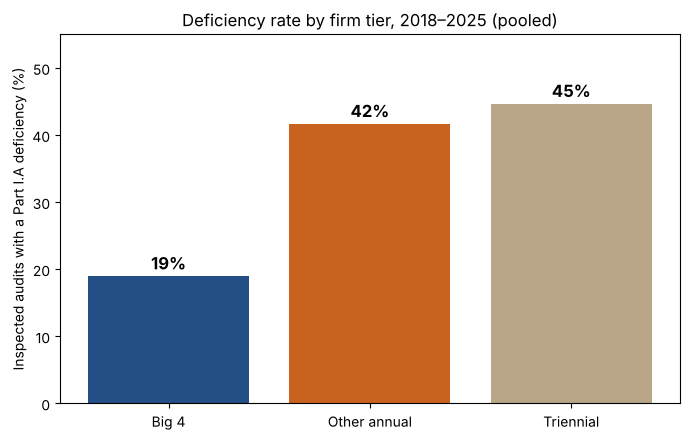

,deficient,reviewed,pooled_rate_pct
tier,,,
Big 4,349.0,1835.0,19.0
Other annual,493.0,1182.0,41.7
Triennial,1015.0,2269.0,44.7


In [9]:
pooled = (s.groupby("tier")
            .agg(deficient=("AuditsWithPartIADeficiencies", "sum"),
                 reviewed=("TotalAuditsReviewed", "sum"))
            .reindex(TIER_ORDER))
pooled["pooled_rate_pct"] = (pooled["deficient"] / pooled["reviewed"] * 100).round(1)
for t in TIER_ORDER:
    facts[f"tier_rate_{t}"] = pooled.loc[t, "pooled_rate_pct"]
    facts[f"tier_counts_{t}"] = (int(pooled.loc[t, "deficient"]), int(pooled.loc[t, "reviewed"]))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(pooled.index, pooled["pooled_rate_pct"], color=[TIER_COLORS[t] for t in TIER_ORDER])
for i, val in enumerate(pooled["pooled_rate_pct"]):
    ax.text(i, val + 1, f"{val:.0f}%", ha="center", fontsize=12, fontweight="bold")
ax.set_ylabel("Inspected audits with a Part I.A deficiency (%)")
ax.set_title("Deficiency rate by firm tier, 2018–2025 (pooled)")
ax.set_ylim(0, 55)
plt.tight_layout()
plt.show()
pooled

## 10. Finding 2: trends over time by tier
The chart stops at the last complete inspection year. A tier's rate is pooled across firms; triennial firms appear only in their inspection years, so each year's triennial group is a **different** set of firms. The "Other annual" line covers only 6–10 firms per year.

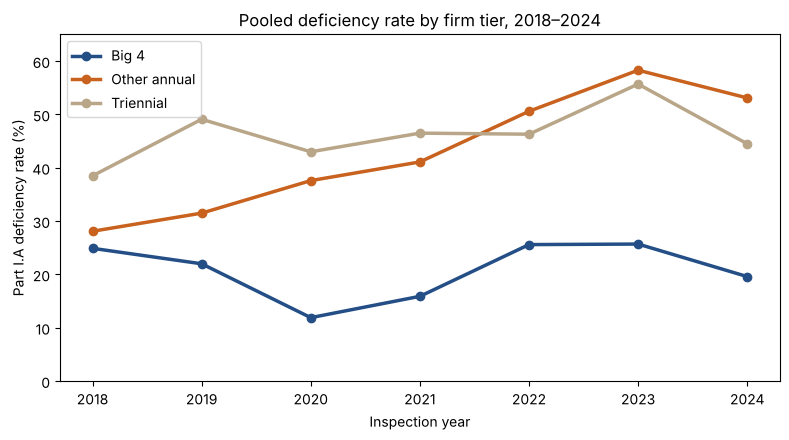

tier,Big 4,Other annual,Triennial
insp_year,,,
2018,24.9,28.1,38.5
2019,22.0,31.5,49.1
2020,11.9,37.6,43.0
2021,15.9,41.1,46.5
2022,25.6,50.6,46.3
2023,25.7,58.3,55.7
2024,19.6,53.1,44.5
2025,7.8,23.5,24.4


In [10]:
trend = (s.groupby(["insp_year", "tier"])
           .agg(deficient=("AuditsWithPartIADeficiencies", "sum"),
                reviewed=("TotalAuditsReviewed", "sum"),
                firms=("firm_id", "nunique"))
           .reset_index())
trend["pooled_rate_pct"] = (trend["deficient"] / trend["reviewed"] * 100).round(1)
trend_table = trend.pivot(index="insp_year", columns="tier", values="pooled_rate_pct")[TIER_ORDER]
facts["trend"] = trend_table

fig, ax = plt.subplots(figsize=(8, 4.5))
for t in TIER_ORDER:
    g = trend_table.loc[:TREND_LAST_YEAR, t]
    ax.plot(g.index, g.values, marker="o", linewidth=2.5, color=TIER_COLORS[t], label=t)
ax.set_xlabel("Inspection year")
ax.set_ylabel("Part I.A deficiency rate (%)")
ax.set_title(f"Pooled deficiency rate by firm tier, {FIRST_INSPECTION_YEAR}–{TREND_LAST_YEAR}")
ax.set_ylim(0, 65)
ax.legend()
plt.tight_layout()
plt.show()

trend_table

## 11. Finding 3: deficiency rates by workload group
Non-Big 4 firms only: Big 4 partners almost all average one to two clients each, so they do not spread across these groups. Groups are based on the **firm's average** clients per signing partner.

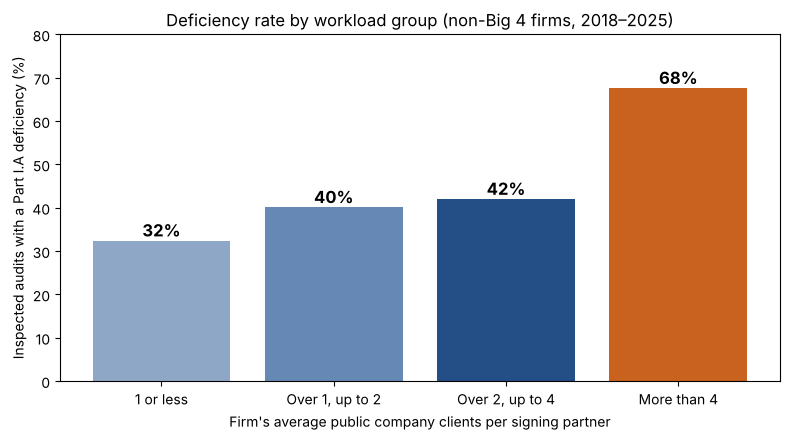

,reports,firms,deficient,reviewed,pooled_rate_pct
workload_group,,,,,
1 or less,374,238,257.0,794.0,32.4
"Over 1, up to 2",269,167,490.0,1223.0,40.1
"Over 2, up to 4",182,116,342.0,814.0,42.0
More than 4,137,74,419.0,620.0,67.6


In [11]:
nb = s[s["tier"] != "Big 4"].copy()
bins = [0, 1, 2, 4, np.inf]
labels = ["1 or less", "Over 1, up to 2", "Over 2, up to 4", "More than 4"]
nb["workload_group"] = pd.cut(nb["clients_per_partner"], bins=bins, labels=labels, right=True)

groups = (nb.groupby("workload_group", observed=True)
            .agg(reports=("firm_id", "size"),
                 firms=("firm_id", "nunique"),
                 deficient=("AuditsWithPartIADeficiencies", "sum"),
                 reviewed=("TotalAuditsReviewed", "sum")))
groups["pooled_rate_pct"] = (groups["deficient"] / groups["reviewed"] * 100).round(1)
facts["nonbig4_reports"] = len(nb)
facts["workload_groups"] = groups

fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#8FA7C7", "#6688B4", "#234E86", "#C8621E"]
ax.bar(groups.index.astype(str), groups["pooled_rate_pct"], color=colors)
for i, val in enumerate(groups["pooled_rate_pct"]):
    ax.text(i, val + 1, f"{val:.0f}%", ha="center", fontsize=12, fontweight="bold")
ax.set_xlabel("Firm's average public company clients per signing partner")
ax.set_ylabel("Inspected audits with a Part I.A deficiency (%)")
ax.set_title("Deficiency rate by workload group (non-Big 4 firms, 2018–2025)")
ax.set_ylim(0, 80)
plt.tight_layout()
plt.show()
groups

**Sensitivity check:** an unweighted rank correlation treats a firm with one inspected audit the same as one with sixty, so it understates the pattern. We report it for completeness.

In [12]:
for t, g in s.groupby("tier"):
    rho = g[["log_cpp", "def_rate"]].corr(method="spearman").iloc[0, 1]
    print(f"{t:13s} n={len(g):4d}  unweighted Spearman correlation = {rho:.2f}")

Big 4         n=  32  unweighted Spearman correlation = 0.07
Other annual  n=  66  unweighted Spearman correlation = 0.31
Triennial     n= 896  unweighted Spearman correlation = 0.26


## 12. The extreme case: highest workload among annually inspected firms
We list the largest workloads, then look at the top firm's history. The SEC's May 3, 2024 action against this firm (press release 2024-51) is cited in our presentation.

In [13]:
cols = ["Company", "Country", "tier", "insp_year", "clients", "partners",
        "clients_per_partner", "TotalAuditsReviewed", "AuditsWithPartIADeficiencies"]
display_top = s.sort_values("clients_per_partner", ascending=False)[cols].head(8)

annual = s[s["tier"] == "Other annual"]
top = annual.loc[annual["clients_per_partner"].idxmax()]
facts["extreme_firm"] = top["Company"]
facts["extreme_year"] = int(top["insp_year"])
facts["extreme_clients"] = int(top["clients"])
facts["extreme_partners"] = int(top["partners"])
facts["extreme_deficient"] = int(top["AuditsWithPartIADeficiencies"])
facts["extreme_reviewed"] = int(top["TotalAuditsReviewed"])
print(f"{facts['extreme_firm']}, inspection year {facts['extreme_year']}: "
      f"{facts['extreme_clients']} clients, {facts['extreme_partners']} signing partner(s), "
      f"{facts['extreme_deficient']} of {facts['extreme_reviewed']} inspected audits deficient")
display_top

B F Borgers CPA PC, inspection year 2023: 182 clients, 1 signing partner(s), 12 of 12 inspected audits deficient


,Company,Country,tier,insp_year,clients,partners,clients_per_partner,TotalAuditsReviewed,AuditsWithPartIADeficiencies
328,B F Borgers CPA PC,United States,Other annual,2023,182.0,1.0,182.000000,12.0,12.0
432,B F Borgers CPA PC,United States,Other annual,2022,172.0,3.0,57.333333,11.0,11.0
603,B F Borgers CPA PC,United States,Triennial,2021,156.0,4.0,39.000000,10.0,10.0
926,B F Borgers CPA PC,United States,Triennial,2019,111.0,3.0,37.000000,9.0,8.0
214,"Victor Mokuolu, CPA PLLC",United States,Triennial,2024,30.0,1.0,30.000000,2.0,2.0
809,"Michael Gillespie & Associates, PLLC",United States,Triennial,2020,28.0,1.0,28.000000,2.0,0.0
405,"M&K CPAS, PLLC",United States,Triennial,2022,78.0,3.0,26.000000,7.0,5.0
273,Olayinka Oyebola & Co (Chartered Accountants),Nigeria,Triennial,2023,25.0,1.0,25.000000,3.0,3.0


## 13. Finding 4: regression
**Model:** for firm *i* in inspection year *t*,

deficiency rate = β₀ + β₁ × log(clients per partner) + tier indicators + year indicators + error

**Variables**
- **Outcome:** Part I.A deficiency rate (deficient audits ÷ audits inspected), 0 to 1.
- **Main variable:** natural log of the firm's average clients per signing partner. On a log scale every doubling is the same step, so β₁ × ln(2) is the change in the deficiency rate when workload doubles.
- **Controls:** firm tier (Big 4 is the baseline) and inspection year, so we compare similar firms in the same year.

**Estimation:** weighted least squares, weighted by audits inspected, so inspections with more audits count more. Standard errors are clustered by firm, because the same firm appears in several years.

We estimate it directly with NumPy so the notebook runs without extra packages. If `statsmodels` is installed, the next cell cross-checks the coefficient.

**Interpretation limits:** an association, not cause. PCAOB selects audits mostly on risk, so the outcome reflects a firm's riskiest engagements.

In [14]:
def wls_clustered(data):
    """Weighted least squares with firm-clustered standard errors."""
    data = data.dropna(subset=["def_rate", "log_cpp"]).copy()
    tiers = pd.get_dummies(pd.Categorical(data["tier"], categories=TIER_ORDER),
                           prefix="tier", drop_first=True).astype(float)
    tiers.index = data.index
    tiers = tiers.loc[:, tiers.sum() > 0]          # drop a tier absent from this sample
    years = pd.get_dummies(data["insp_year"].astype(int), prefix="year", drop_first=True).astype(float)
    X = pd.concat([pd.Series(1.0, index=data.index, name="const"), data["log_cpp"], tiers, years], axis=1)

    y = data["def_rate"].to_numpy()
    w = data["TotalAuditsReviewed"].to_numpy(dtype=float)
    Xm = X.to_numpy()
    bread = np.linalg.inv(Xm.T @ (Xm * w[:, None]))
    beta = bread @ (Xm.T @ (w * y))
    resid = y - Xm @ beta

    meat = np.zeros((Xm.shape[1], Xm.shape[1]))
    for idx in data.groupby("firm_id").indices.values():
        score = (Xm[idx] * (w[idx] * resid[idx])[:, None]).sum(axis=0)
        meat += np.outer(score, score)
    n, k = Xm.shape
    G = data["firm_id"].nunique()
    V = (G / (G - 1)) * ((n - 1) / (n - k)) * bread @ meat @ bread
    se = np.sqrt(np.diag(V))
    out = pd.DataFrame({"coef": beta, "se": se, "t": beta / se}, index=X.columns)
    return out, n, G

results, n_obs, n_firms = wls_clustered(s)
b, se = results.loc["log_cpp", "coef"], results.loc["log_cpp", "se"]
facts["reg_coef"] = round(b, 3)
facts["reg_se"] = round(se, 3)
facts["doubling_pts"] = b * np.log(2) * 100
facts["doubling_low"] = (b - 1.96 * se) * np.log(2) * 100
facts["doubling_high"] = (b + 1.96 * se) * np.log(2) * 100

print(f"Observations: {n_obs} inspection reports, {n_firms} firms")
print(f"log(clients per partner): coefficient {b:.4f}, clustered SE {se:.4f}, t = {b/se:.1f}")
print(f"Doubling clients per partner -> {facts['doubling_pts']:+.1f} percentage points "
      f"(95% range {facts['doubling_low']:+.1f} to {facts['doubling_high']:+.1f})")
results.loc[["const", "log_cpp"] + [c for c in results.index if c.startswith("tier_")]].round(4)

Observations: 994 inspection reports, 458 firms
log(clients per partner): coefficient 0.1475, clustered SE 0.0172, t = 8.6
Doubling clients per partner -> +10.2 percentage points (95% range +7.9 to +12.6)


,coef,se,t
const,0.0767,0.0407,1.8872
log_cpp,0.1475,0.0172,8.5671
tier_Other annual,0.1545,0.0612,2.5239
tier_Triennial,0.2258,0.0341,6.6243


In [15]:
# Optional cross-check with statsmodels (pip install statsmodels)
try:
    import statsmodels.formula.api as smf
    reg = s.dropna(subset=["def_rate", "log_cpp"])
    sm_fit = smf.wls("def_rate ~ log_cpp + C(tier) + C(insp_year)", data=reg,
                     weights=reg["TotalAuditsReviewed"]).fit(cov_type="cluster",
                                                             cov_kwds={"groups": reg["firm_id"]})
    print("statsmodels coefficient on log_cpp: %.4f (NumPy: %.4f)" % (sm_fit.params["log_cpp"], b))
    print("statsmodels clustered SE:           %.4f (NumPy: %.4f)" % (sm_fit.bse["log_cpp"], se))
except ImportError:
    print("statsmodels not installed; NumPy results above stand on their own.")

statsmodels not installed; NumPy results above stand on their own.


### Robustness: does the result hold on other samples?
Each row re-estimates the same model on a different sample. These are the numbers on the Finding 4 slide.

In [16]:
samples = {
    "Main sample": s,
    "U.S. firms only": s[s["Country"] == "United States"],
    f"Without {LAST_INSPECTION_YEAR} (incomplete year)": s[s["insp_year"] < LAST_INSPECTION_YEAR],
    f"Without {facts['extreme_firm']}": s[s["Company"] != facts["extreme_firm"]],
    "Without workloads above 20": s[s["clients_per_partner"] <= 20],
}
rows = []
for name, data in samples.items():
    r, n, G = wls_clustered(data)
    coef = r.loc["log_cpp", "coef"]
    rows.append({"sample": name, "reports": n, "firms": G, "coef": round(coef, 4),
                 "se": round(r.loc["log_cpp", "se"], 4),
                 "doubling_pts": round(coef * np.log(2) * 100, 1)})
robust = pd.DataFrame(rows).set_index("sample")
facts["robust"] = robust
robust

,reports,firms,coef,se,doubling_pts
sample,,,,,
Main sample,994,458,0.1475,0.0172,10.2
U.S. firms only,604,251,0.1131,0.0216,7.8
Without 2025 (incomplete year),917,453,0.1504,0.0177,10.4
Without B F Borgers CPA PC,990,457,0.1473,0.0205,10.2
Without workloads above 20,981,456,0.1697,0.0173,11.8


## 14. Tests: every number in the presentation
Each check compares a figure as shown on a slide with the value computed above. If the data or code changes, a failed check flags the slide that needs updating. Rounding follows the slide (whole percents, whole points).

In [17]:
checks = []
def check(slide, label, shown, computed, tol=0.5):
    ok = abs(float(shown) - float(computed)) <= tol
    checks.append({"slide": slide, "figure": label, "on slide": shown,
                   "computed": round(float(computed), 2), "pass": ok})

# Title, summary and data slides
check("1, 2, 6", "Audit firms in sample", 458, facts["sample_firms"], tol=0)
check("2, 6", "Inspection reports in sample", 994, facts["sample_reports"], tol=0)
check("6", "Regular public company audit reports (Form AP)", 86790, facts["regular_audits_kept"], tol=0)

# Cleaning slide
check("7", "Firm ID match rate (%)", 97, facts["firm_id_match_pct"])
check("7", "Superseded amendments removed", 5637, facts["amendments_removed"], tol=0)
check("7", "Dates that failed to parse", 0, facts["dates_unparsed"], tol=0)
check("7", "Missing Issuer IDs filled", 1082, facts["missing_issuer_id"], tol=0)
check("7", "Unmatched small-firm reports", 240, facts["unmatched_triennial"], tol=0)
check("7 (notes)", "Client-count correlation", 0.93, facts["validation_client_corr"], tol=0.005)
check("10 (notes)", "Reports published for latest year", 104, facts["reports_last_year"], tol=0)

# Finding 1
check("2, 8", "Big 4 deficiency rate (%)", 19, facts["tier_rate_Big 4"])
check("8", "Other large firms deficiency rate (%)", 42, facts["tier_rate_Other annual"])
check("2, 8", "Smaller firms deficiency rate (%)", 45, facts["tier_rate_Triennial"])
check("8", "Big 4 deficient audits", 349, facts["tier_counts_Big 4"][0], tol=0)
check("8", "Big 4 audits inspected", 1835, facts["tier_counts_Big 4"][1], tol=0)

# Finding 2 (trend endpoints quoted in the legend)
tt = facts["trend"]
check("9", "Other large firms, 2018 (%)", 28, tt.loc[2018, "Other annual"])
check("9", "Other large firms, 2023 (%)", 58, tt.loc[2023, "Other annual"])
check("9", "Smaller firms, 2018 (%)", 39, tt.loc[2018, "Triennial"])
check("9", "Smaller firms, 2023 (%)", 56, tt.loc[2023, "Triennial"])
check("9", "Big 4 low, 2018-2024 (%)", 12, tt.loc[:TREND_LAST_YEAR, "Big 4"].min())
check("9", "Big 4 high, 2018-2024 (%)", 26, tt.loc[:TREND_LAST_YEAR, "Big 4"].max())

# Finding 3
wg = facts["workload_groups"]["pooled_rate_pct"]
check("2, 10", "Workload 1 or less (%)", 32, wg.iloc[0])
check("10", "Workload over 1 to 2 (%)", 40, wg.iloc[1])
check("10", "Workload over 2 to 4 (%)", 42, wg.iloc[2])
check("2, 10", "Workload more than 4 (%)", 68, wg.iloc[3])
check("10", "Non-Big 4 reports", 962, facts["nonbig4_reports"], tol=0)

# Extreme case
check("11", "Extreme firm: clients", 182, facts["extreme_clients"], tol=0)
check("11", "Extreme firm: signing partners", 1, facts["extreme_partners"], tol=0)
check("11", "Extreme firm: deficient audits", 12, facts["extreme_deficient"], tol=0)
check("11", "Extreme firm: audits inspected", 12, facts["extreme_reviewed"], tol=0)
check("11", "Extreme firm: inspection year", 2023, facts["extreme_year"], tol=0)

# Finding 4
rb = facts["robust"]["doubling_pts"]
check("2, 12", "Doubling effect (points)", 10, facts["doubling_pts"])
check("12", "Likely range, low (points)", 8, facts["doubling_low"])
check("12", "Likely range, high (points)", 13, facts["doubling_high"])
check("12 (notes)", "Coefficient on log workload", 0.148, facts["reg_coef"], tol=0.0005)
check("12 (notes)", "Clustered standard error", 0.017, facts["reg_se"], tol=0.0005)
check("12", "U.S. firms only (points)", 8, rb.iloc[1])
check("12", "Without latest year (points)", 10, rb.iloc[2])
check("12", "Without extreme firm (points)", 10, rb.iloc[3])

# Data-integrity checks
checks.append({"slide": "-", "figure": "One report per firm per year", "on slide": "",
               "computed": int(s.duplicated(["firm_id", "insp_year"]).sum()),
               "pass": not s.duplicated(["firm_id", "insp_year"]).any()})
checks.append({"slide": "-", "figure": "Deficiency rates between 0 and 1", "on slide": "",
               "computed": "", "pass": bool(s["def_rate"].between(0, 1).all())})
checks.append({"slide": "-", "figure": "Every firm-year has at least one partner", "on slide": "",
               "computed": "", "pass": bool((s["partners"] >= 1).all())})

test_table = pd.DataFrame(checks)
print(f"{test_table['pass'].sum()} of {len(test_table)} checks passed")
if not test_table["pass"].all():
    print(test_table[~test_table["pass"]])
assert test_table["pass"].all(), "A presentation figure no longer matches the data. See the table."
test_table

42 of 42 checks passed


,slide,figure,on slide,computed,pass
0,"1, 2, 6",Audit firms in sample,458,458.0,True
1,"2, 6",Inspection reports in sample,994,994.0,True
2,6,Regular public company audit reports (Form AP),86790,86790.0,True
3,7,Firm ID match rate (%),97,97.0,True
4,7,Superseded amendments removed,5637,5637.0,True
5,7,Dates that failed to parse,0,0.0,True
6,7,Missing Issuer IDs filled,1082,1082.0,True
7,7,Unmatched small-firm reports,240,240.0,True
8,7 (notes),Client-count correlation,0.93,0.93,True
9,10 (notes),Reports published for latest year,104,104.0,True


## 15. Save the cleaned firm-year file
Firm-level data only (no partner or client details).

In [18]:
keep = ["firm_id", "Company", "Country", "tier", "insp_year", "fiscal_year",
        "TotalAuditsReviewed", "AuditsWithPartIADeficiencies", "def_rate",
        "clients", "partners", "clients_per_partner", "log_cpp"]
s[keep].to_csv(f"{DATA_DIR}/firm_year_analysis.csv", index=False)
print("Saved", len(s), "rows to firm_year_analysis.csv")

Saved 994 rows to firm_year_analysis.csv
